# Redes neurais: imagens e descritores versus SVM

Comparação auxiliar, sem alterar o modelo ou as submissões do caderno oficial.

- **MLP:** recebe as mesmas 14 features originais; camadas 64 → 32 → 5.
- **CNN:** recebe a imagem RGB 48 × 48; três blocos convolucionais, treinados do zero.
- **Referência:** SVM vencedor do `D2_Visao_COLAB.ipynb` atual (C=10, gamma=0,1, balanced). Não comparar o CV de outro notebook com a validação desta rodada.
- Mesmas 1.720 imagens de treino e 430 de validação, split estratificado com semente 42.
- Épocas escolhidas pelo F1-macro em uma divisão **interna do treino**; depois retreino do zero nas 1.720 imagens. Padronização e pesos de classes ajustados apenas no treino pertinente.
- Três sementes fixadas antes dos resultados. Reportamos média, desvio e intervalo observado, não apenas a melhor execução.

Sem novas features, pré-treino, augmentation ou busca extensa nesta primeira comparação. CPU, até 120 épocas na MLP e 60 na CNN, paciência 12; pode levar alguns minutos.

## Como executar

Rode as células na ordem. O notebook é independente do arquivo `redes_neurais.py` (que oferece a mesma implementação para terminal/testes). Os dados são procurados na pasta atual e nas pastas acima; se ausentes, baixa somente o treino da URL oficial.

Dependências: `torch`, `numpy`, `pandas`, `scikit-learn`, `matplotlib`. No Colab, se faltar alguma, use uma célula com `%pip install torch numpy pandas scikit-learn matplotlib`. Localmente use apenas o `.venv` do projeto.


In [1]:
"""Experimento auxiliar: MLP tabular e CNN RGB versus o SVM do caderno atual.

Não altera o notebook oficial, os dados nem as submissões.
"""
from pathlib import Path
import hashlib
import json
import random
from time import perf_counter

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

CLASSES = ["papel", "papelao", "plastico", "vidro", "metal"]
COLUNAS = ["vermelho_medio", "verde_medio", "azul_medio",
           "vermelho_variacao", "verde_variacao", "azul_variacao",
           "brilho_medio", "contraste", "brilho_alto", "amplitude_luz",
           "bordas", "saturacao_media", "saturacao_variacao", "area_reluzente"]
URL_TREINO = "https://drive.google.com/uc?export=download&id=1lJRXzTupXGUrn3R6tdnA7ulROYEEe7RX"




In [2]:
def extrair_originais(fotos):
    """Mesmas 14 medidas, ordem e operações do D2_Visao_COLAB.ipynb."""
    linhas = []
    for im in fotos:
        cinza = im.mean(axis=2)
        gx = np.abs(np.diff(cinza, axis=1)).mean()
        gy = np.abs(np.diff(cinza, axis=0)).mean()
        mx, mn = im.max(axis=2), im.min(axis=2)
        satur = np.where(mx > 0, (mx-mn)/(mx+1e-6), 0)
        linhas.append([im[..., 0].mean(), im[..., 1].mean(), im[..., 2].mean(),
                       im[..., 0].std(), im[..., 1].std(), im[..., 2].std(),
                       cinza.mean(), cinza.std(), np.percentile(cinza, 95),
                       np.percentile(cinza, 95)-np.percentile(cinza, 5),
                       (gx+gy)/2, satur.mean(), satur.std(), (cinza > .80).mean()])
    return pd.DataFrame(linhas, columns=COLUNAS)


def localizar_treino(pasta=None, baixar=False):
    if pasta is not None:
        candidatos = [Path(pasta).resolve()]
    else:
        candidatos = [Path.cwd(), *Path.cwd().parents]
        if "__file__" in globals():
            origem = Path(__file__).resolve().parent
            candidatos.extend([origem, *origem.parents])
    for origem in candidatos:
        arquivo = origem / "treino_fotos.npz"
        if arquivo.is_file():
            return arquivo
    if baixar:
        import urllib.request
        arquivo = candidatos[0] / "treino_fotos.npz"
        urllib.request.urlretrieve(URL_TREINO, arquivo)
        return arquivo
    raise FileNotFoundError("Informe pasta_dados ou envie treino_fotos.npz para a pasta do notebook.")


def fixar_semente(semente):
    random.seed(semente)
    np.random.seed(semente)
    torch.manual_seed(semente)
    torch.use_deterministic_algorithms(True)




In [3]:
def criar_rede(tipo):
    if tipo == "MLP":
        return nn.Sequential(nn.Linear(14, 64), nn.ReLU(), nn.Dropout(.2),
                             nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 5))
    if tipo == "CNN":
        return nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((3, 3)), nn.Flatten(),
            nn.Linear(64*3*3, 64), nn.ReLU(), nn.Dropout(.25), nn.Linear(64, 5))
    raise ValueError(f"Rede desconhecida: {tipo}")


def ajustar_normalizacao(dados, tipo):
    """Recebe exclusivamente o subconjunto de treino do ajuste em questão."""
    if tipo == "MLP":
        scaler = StandardScaler().fit(dados)
        return {"media": scaler.mean_.astype(np.float32),
                "escala": scaler.scale_.astype(np.float32)}
    return {"media": dados.mean(axis=(0, 1, 2), keepdims=True),
            "escala": np.maximum(dados.std(axis=(0, 1, 2), keepdims=True), 1e-6)}


def transformar(dados, tipo, normalizacao):
    x = ((dados-normalizacao["media"])/normalizacao["escala"]).astype(np.float32)
    if tipo == "CNN":
        x = x.transpose(0, 3, 1, 2)
    if not np.isfinite(x).all():
        raise ValueError("Entradas não finitas após normalização.")
    return torch.from_numpy(np.ascontiguousarray(x))


def preparar_treino(tipo, dados, alvos, semente):
    fixar_semente(semente)
    normalizacao = ajustar_normalizacao(dados, tipo)
    x = transformar(dados, tipo, normalizacao)
    y = torch.tensor(alvos, dtype=torch.long)
    gerador = torch.Generator().manual_seed(semente)
    loader = DataLoader(TensorDataset(x, y), batch_size=64, shuffle=True,
                        generator=gerador, num_workers=0)
    rede = criar_rede(tipo)  # CPU: dispensa CUDA e mantém o experimento acessível.
    contagens = np.bincount(alvos, minlength=len(CLASSES))
    if (contagens == 0).any():
        raise ValueError("Todas as classes devem aparecer no treino.")
    pesos = torch.tensor(len(alvos)/(len(CLASSES)*contagens), dtype=torch.float32)
    perda = nn.CrossEntropyLoss(weight=pesos)
    otimizador = torch.optim.AdamW(rede.parameters(), lr=1e-3, weight_decay=1e-3)
    return rede, normalizacao, loader, perda, otimizador


def treinar_epoca(rede, loader, perda, otimizador):
    rede.train()
    total = 0.0
    for x, y in loader:
        otimizador.zero_grad(set_to_none=True)
        loss = perda(rede(x), y)
        if not torch.isfinite(loss):
            raise FloatingPointError("Perda não finita.")
        loss.backward()
        otimizador.step()
        total += float(loss.detach())*len(y)
    return total/len(loader.dataset)


def prever(rede, dados, tipo, normalizacao):
    rede.eval()
    entradas = transformar(dados, tipo, normalizacao)
    with torch.no_grad():
        return torch.cat([rede(x).argmax(1) for x in entradas.split(128)]).numpy()




In [4]:
def selecionar_epocas(tipo, dados, alvos, internos, parada, semente, max_epocas, paciencia):
    """Não recebe os índices nem os rótulos da validação externa."""
    rede, norm, loader, perda, opt = preparar_treino(tipo, dados[internos], alvos[internos], semente)
    historico, melhor_f1, melhor_epoca, espera = [], -1., 1, 0
    for epoca in range(1, max_epocas+1):
        loss = treinar_epoca(rede, loader, perda, opt)
        pred = prever(rede, dados[parada], tipo, norm)
        score = f1_score(alvos[parada], pred, labels=np.arange(5), average="macro", zero_division=0)
        historico.append({"epoca": epoca, "loss_treino": loss, "f1_interno": float(score)})
        if score > melhor_f1+1e-4:
            melhor_f1, melhor_epoca, espera = score, epoca, 0
        else:
            espera += 1
        if espera >= paciencia:
            break
    return melhor_epoca, historico


def metricas(alvos, pred):
    return {"f1_validacao": float(f1_score(alvos, pred, labels=np.arange(5), average="macro", zero_division=0)),
            "acuracia": float(accuracy_score(alvos, pred)),
            "f1_por_classe": dict(zip(CLASSES, f1_score(alvos, pred, labels=np.arange(5), average=None, zero_division=0).tolist())),
            "matriz_confusao": confusion_matrix(alvos, pred, labels=np.arange(5)).tolist()}


def executar_experimento(pasta_dados=None, sementes=(42, 137, 2026),
                        epocas_mlp=120, epocas_cnn=60, paciencia=12,
                        pasta_saida=None, baixar=False):
    if not sementes or len(set(sementes)) != len(sementes):
        raise ValueError("Use pelo menos uma semente, sem duplicatas.")
    if min(epocas_mlp, epocas_cnn, paciencia) < 1:
        raise ValueError("Épocas e paciência devem ser positivas.")
    torch.set_num_threads(min(4, torch.get_num_threads()))
    arquivo = localizar_treino(pasta_dados, baixar)
    hash_antes = hashlib.sha256(arquivo.read_bytes()).hexdigest()
    with np.load(arquivo, allow_pickle=False) as pacote:
        fotos = pacote["fotos"].astype(np.float32)/255.0
        rotulos = pacote["rotulos"].copy()
    assert fotos.shape[1:] == (48, 48, 3) and np.isfinite(fotos).all()
    assert set(rotulos) == set(CLASSES) and 0 <= fotos.min() <= fotos.max() <= 1
    y = np.array([CLASSES.index(c) for c in rotulos])
    X = extrair_originais(fotos)
    treino, valida = train_test_split(np.arange(len(y)), test_size=.2, random_state=42, stratify=rotulos)
    internos, parada = train_test_split(np.arange(len(treino)), test_size=.2,
                                       random_state=137, stratify=y[treino])
    assert set(treino).isdisjoint(valida)
    assert set(internos).isdisjoint(parada)
    assert set(treino[np.r_[internos, parada]]) == set(treino)
    destino = Path(pasta_saida) if pasta_saida is not None else None
    if destino is not None:
        destino.mkdir(parents=True, exist_ok=True)

    # Configuração vencedora já registrada no notebook atual; não repetir a busca.
    svm = make_pipeline(StandardScaler(), SVC(C=10, gamma=.1, kernel="rbf", class_weight="balanced", random_state=42))
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(svm, X.iloc[treino], rotulos[treino], cv=cv, scoring="f1_macro", n_jobs=1)
    svm.fit(X.iloc[treino], rotulos[treino])
    pred_svm = np.array([CLASSES.index(c) for c in svm.predict(X.iloc[valida])])
    baseline = {"modelo": "SVM anterior", **metricas(y[valida], pred_svm),
                "f1_cv": float(scores.mean()), "scores_cv": scores.tolist(),
                "parametros": {"C": 10, "gamma": .1, "kernel": "rbf", "class_weight": "balanced"}}
    print(f"SVM reproduzido: CV={scores.mean():.4f}; validação={baseline['f1_validacao']:.4f}", flush=True)
    resultados, artefatos = [], {}
    for tipo, dados, teto in [("MLP", X.to_numpy(dtype=np.float32), epocas_mlp), ("CNN", fotos, epocas_cnn)]:
        for semente in sementes:
            inicio = perf_counter()
            print(f"{tipo}, semente {semente}: seleção de épocas no treino interno...", flush=True)
            epocas, historico = selecionar_epocas(tipo, dados[treino], y[treino], internos, parada,
                                                 semente, teto, paciencia)
            # Recomeçar do zero, agora com TODO o treino externo e épocas fixadas.
            rede, norm, loader, perda, opt = preparar_treino(tipo, dados[treino], y[treino], semente)
            for _ in range(epocas):
                treinar_epoca(rede, loader, perda, opt)
            pred = prever(rede, dados[valida], tipo, norm)
            r = {"modelo": tipo, "semente": int(semente), "epocas": epocas,
                 "segundos": perf_counter()-inicio, **metricas(y[valida], pred),
                 "previsoes": pred.tolist(), "historico_interno": historico}
            resultados.append(r)
            artefatos[(tipo, semente)] = (rede, norm)
            if destino is not None:
                torch.save({"state_dict": rede.state_dict(), "tipo": tipo, "classes": CLASSES,
                            "media": torch.from_numpy(norm["media"]), "escala": torch.from_numpy(norm["escala"])},
                           destino / f"{tipo.lower()}_semente_{semente}.pt")
            print(f"{tipo}, semente {semente}: {epocas} épocas; F1 validação={r['f1_validacao']:.4f}", flush=True)

    resumo = [{"modelo": "SVM anterior", "F1 médio validação": baseline["f1_validacao"],
               "desvio entre sementes": 0., "mínimo": baseline["f1_validacao"],
               "máximo": baseline["f1_validacao"], "delta vs SVM": 0.}]
    for tipo in ("MLP", "CNN"):
        valores = np.array([r["f1_validacao"] for r in resultados if r["modelo"] == tipo])
        resumo.append({"modelo": tipo, "F1 médio validação": float(valores.mean()),
                       "desvio entre sementes": float(valores.std()), "mínimo": float(valores.min()),
                       "máximo": float(valores.max()), "delta vs SVM": float(valores.mean()-baseline["f1_validacao"])})
    assert hashlib.sha256(arquivo.read_bytes()).hexdigest() == hash_antes
    relatorio = {"baseline": baseline, "resultados": resultados, "resumo": resumo,
                 "classes": CLASSES, "colunas_mlp": COLUNAS, "sementes": list(sementes),
                 "indices_treino": treino.tolist(), "indices_validacao": valida.tolist(),
                 "indices_treino_interno": treino[internos].tolist(), "indices_parada": treino[parada].tolist(),
                 "rotulos_validacao": y[valida].tolist(), "previsoes_svm": pred_svm.tolist(),
                 "sha256_dados": hash_antes, "torch": torch.__version__,
                 "protocolo": "80/20 estratificado seed42; épocas em 20% interno seed137; refit treino completo; CPU; sem augmentation",
                 "limite": "Validação reutilizada historicamente; sementes não são folds nem prova de significância. Sem CV das redes nesta rodada."}
    if destino is not None:
        with (destino / "comparacao.json").open("w", encoding="utf-8") as f:
            json.dump(relatorio, f, ensure_ascii=False, indent=2, allow_nan=False)
    return relatorio, artefatos



In [5]:
# Configuração fixada antes de observar a validação externa.
SEMENTES_REDES = (42, 137, 2026)
relatorio_redes, modelos_redes = executar_experimento(
    sementes=SEMENTES_REDES, epocas_mlp=120, epocas_cnn=60, paciencia=12,
    pasta_saida="resultados_redes_neurais", baixar=True,
)
print("Resultados e pesos salvos em resultados_redes_neurais; nenhuma submissão gerada.")


SVM reproduzido: CV=0.7325; validação=0.7266
MLP, semente 42: seleção de épocas no treino interno...
MLP, semente 42: 110 épocas; F1 validação=0.7074
MLP, semente 137: seleção de épocas no treino interno...
MLP, semente 137: 71 épocas; F1 validação=0.6969
MLP, semente 2026: seleção de épocas no treino interno...
MLP, semente 2026: 62 épocas; F1 validação=0.6950
CNN, semente 42: seleção de épocas no treino interno...
CNN, semente 42: 26 épocas; F1 validação=0.7344
CNN, semente 137: seleção de épocas no treino interno...
CNN, semente 137: 47 épocas; F1 validação=0.7497
CNN, semente 2026: seleção de épocas no treino interno...
CNN, semente 2026: 37 épocas; F1 validação=0.7113
Resultados e pesos salvos em resultados_redes_neurais; nenhuma submissão gerada.


In [6]:
comparacao_redes = pd.DataFrame(relatorio_redes["resumo"])
display(comparacao_redes.round(4))
display(pd.DataFrame(relatorio_redes["resultados"])[
    ["modelo","semente","epocas","f1_validacao","acuracia","segundos"]].round(4))
por_classe = {"SVM anterior": relatorio_redes["baseline"]["f1_por_classe"]}
for tipo in ("MLP","CNN"):
    por_classe[tipo+" (média sementes)"] = pd.DataFrame([
        r["f1_por_classe"] for r in relatorio_redes["resultados"] if r["modelo"]==tipo
    ]).mean().to_dict()
display(pd.DataFrame(por_classe).reindex(CLASSES).round(4))
vencedor = comparacao_redes.sort_values("F1 médio validação",ascending=False).iloc[0]
print(f"Maior F1 médio observado: {vencedor['modelo']} = {vencedor['F1 médio validação']:.4f}")
print("O desvio mede variação entre inicializações, NÃO incerteza de generalização.")
print("Esta rodada não calcula CV das redes e não substitui automaticamente o SVM.")
print(relatorio_redes["limite"])


,modelo,F1 médio validação,desvio entre sementes,mínimo,máximo,delta vs SVM
0,SVM anterior,0.7266,0.0000,0.7266,0.7266,0.0000
1,MLP,0.6998,0.0055,0.6950,0.7074,-0.0268
2,CNN,0.7318,0.0158,0.7113,0.7497,0.0052


,modelo,semente,epocas,f1_validacao,acuracia,segundos
0,MLP,42,110,0.7074,0.7140,75.8299
1,MLP,137,71,0.6969,0.7000,37.7333
2,MLP,2026,62,0.6950,0.7000,32.9656
3,CNN,42,26,0.7344,0.7349,194.7081
4,CNN,137,47,0.7497,0.7558,306.9337
5,CNN,2026,37,0.7113,0.7140,262.9384


,SVM anterior,MLP (média sementes),CNN (média sementes)
papel,0.7857,0.7719,0.8346
papelao,0.7770,0.7579,0.7804
plastico,0.7317,0.7003,0.7030
vidro,0.7191,0.6714,0.6974
metal,0.6194,0.5974,0.6436


Maior F1 médio observado: CNN = 0.7318
O desvio mede variação entre inicializações, NÃO incerteza de generalização.
Esta rodada não calcula CV das redes e não substitui automaticamente o SVM.
Validação reutilizada historicamente; sementes não são folds nem prova de significância. Sem CV das redes nesta rodada.


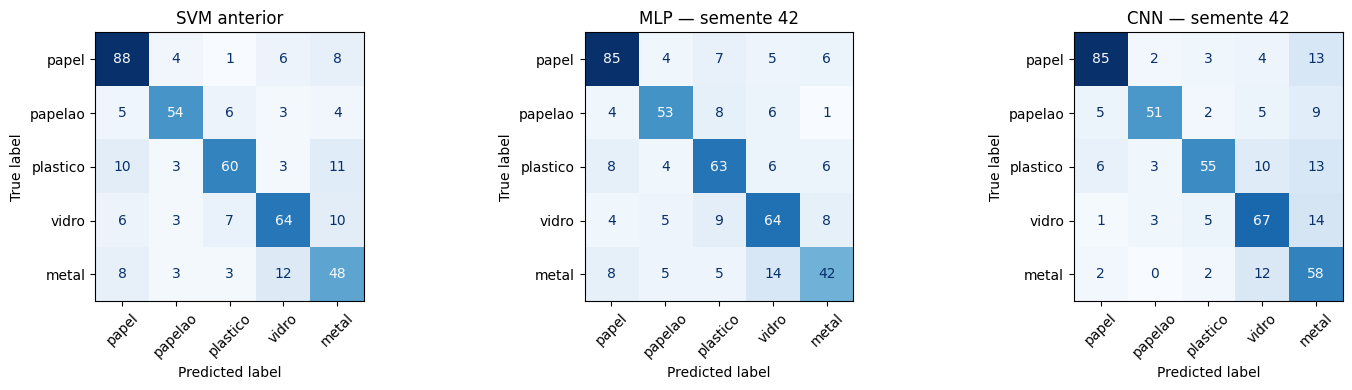

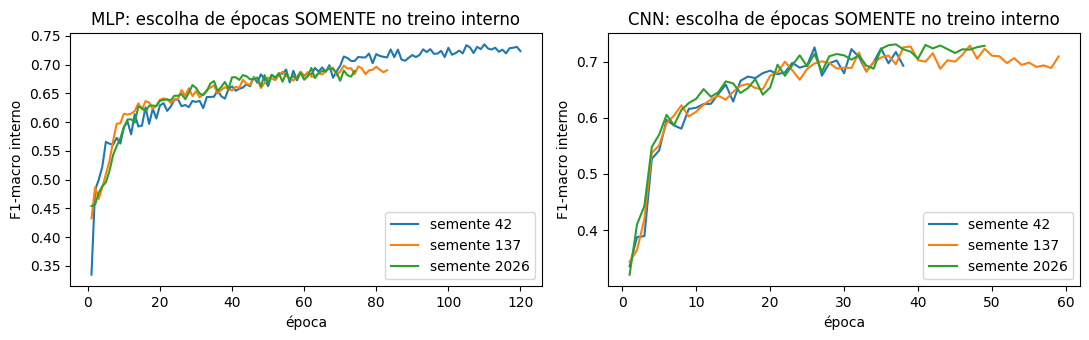

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1,3,figsize=(15,4))
matrizes = [("SVM anterior",relatorio_redes["baseline"]["matriz_confusao"])]
for tipo in ("MLP","CNN"):
    r = next(r for r in relatorio_redes["resultados"] if r["modelo"]==tipo and r["semente"]==SEMENTES_REDES[0])
    matrizes.append((f"{tipo} — semente {SEMENTES_REDES[0]}",r["matriz_confusao"]))
for ax,(nome,cm) in zip(axes,matrizes):
    ConfusionMatrixDisplay(np.array(cm),display_labels=CLASSES).plot(ax=ax,colorbar=False,cmap="Blues")
    ax.set_title(nome); ax.tick_params(axis="x",rotation=45)
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1,2,figsize=(11,3.5))
for ax,tipo in zip(axes,("MLP","CNN")):
    for r in relatorio_redes["resultados"]:
        if r["modelo"]==tipo:
            h=pd.DataFrame(r["historico_interno"])
            ax.plot(h["epoca"],h["f1_interno"],label=f"semente {r['semente']}")
    ax.set_title(f"{tipo}: escolha de épocas SOMENTE no treino interno")
    ax.set_xlabel("época"); ax.set_ylabel("F1-macro interno"); ax.legend()
fig.tight_layout(); plt.show()


## Interpretação

As matrizes das redes usam a primeira semente pré-definida (42), não a que obteve maior F1. A tabela principal usa todas as sementes.

O SVM já teve hiperparâmetros ajustados; estas são arquiteturas iniciais, não uma busca equivalente. A comparação mede as configurações avaliadas, não prova que uma família seja superior em geral. A validação já foi consultada em experimentos anteriores: nenhum ganho aqui, sozinho, comprova significância ou desempenho no teste oficial.

Os modelos aprendem cinco classes, incluindo papelão, conforme os dados e o notebook atual. Nenhum rótulo do teste oculto é utilizado.
